In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

import kagglehub
import pathlib
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import numpy as np
import pathlib
import cv2
from sklearn.utils import shuffle
import tensorflow as tf
from collections import Counter
from keras.src.legacy.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras import datasets, layers, models

In [2]:
RAMDOM_STATE = 42
BATCH_SIZE= 32
EPOCHS = 15

In [3]:
extensions_valides = (".jpg", ".jpeg", ".png", ".bmp")

labels_par_dossier = {
    "glioma": 0,
    "meningioma": 1,
    "notumor" : 2,
    "pituitary" : 3
}

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("devana2004/dataset")

path = path +'/Data'
print("Path to dataset files:", path)


Path to dataset files: /kaggle/input/datasets/devana2004/dataset/Data


In [5]:

def check_data(path, extensions_valides, labels_par_dossier):
    num_skiped = 0
    num_corrompu = 0
    images= []
    labels = []
    try:
        data_dir = pathlib.Path(path)
        for folder in data_dir.iterdir():
            if folder.is_dir():
                for file in folder.iterdir():
                    if folder.name in labels_par_dossier.keys():
                        
                        if file.is_file() and not file.name.lower().endswith(extensions_valides):
                            num_skiped +=1
                            continue
                        else:
                            image = cv2.imread(str(file))
                            if image is None:
                                num_corrompu +=1
                                continue
                            else:
                                images.append(image)
                                label = labels_par_dossier[folder.name]
                                labels.append(label)

        print('nombre de fichiers invlaid', num_skiped)
        print('nombre de fichiers corrompus', num_corrompu)
    except (FileNotFoundError):
        print("Erreur : Le fichier n'existe pas.")
    except Exception as e:
        # Capture toute autre erreur inattendue
        print(f"Erreur inattendue : {e}")
    return images, labels

images, labels = check_data(path, extensions_valides,  labels_par_dossier)

nombre de fichiers invlaid 0
nombre de fichiers corrompus 0


In [6]:
image_size = (224, 224)
def preparing_data(image_size):
    images_resized =[]
    for image in images:
        resized = cv2.resize(image, image_size, interpolation=cv2.INTER_LINEAR)
        images_resized.append(resized)
    
    images_array_2d = np.array(images_resized)
    
    labeles_array_2d = np.array(labels)
    
    return images_array_2d, labeles_array_2d

images_array_2d, labeles_array_2d = preparing_data(image_size)
print(images_array_2d.shape, labeles_array_2d.shape)

(7023, 224, 224, 3) (7023,)


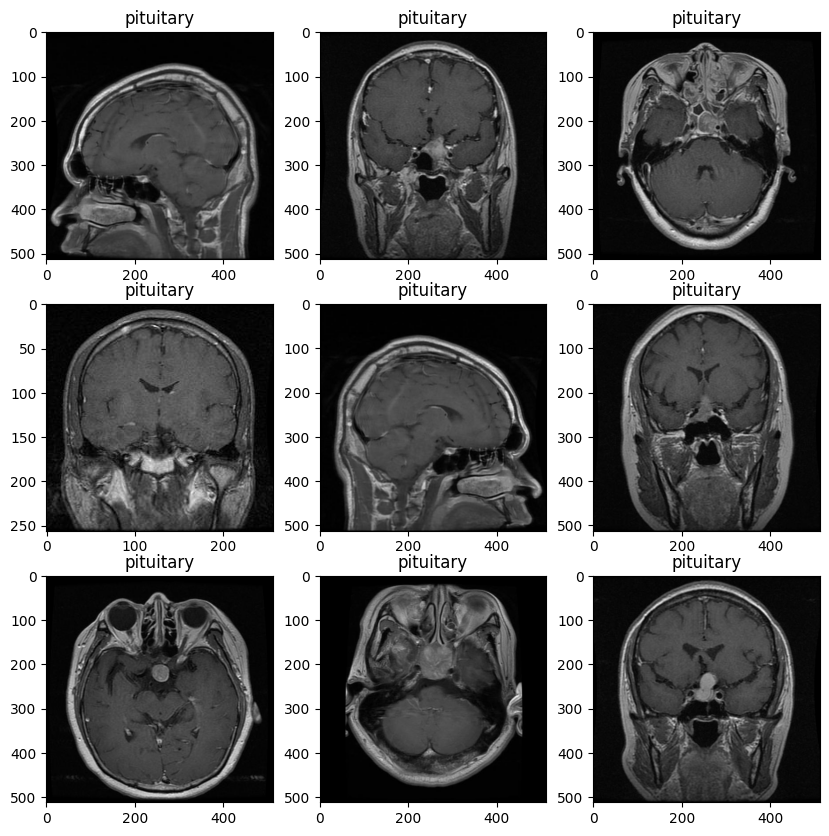

glioma : 1621 images
meningioma : 1645 images
notumor : 2000 images
pituitary : 1757 images


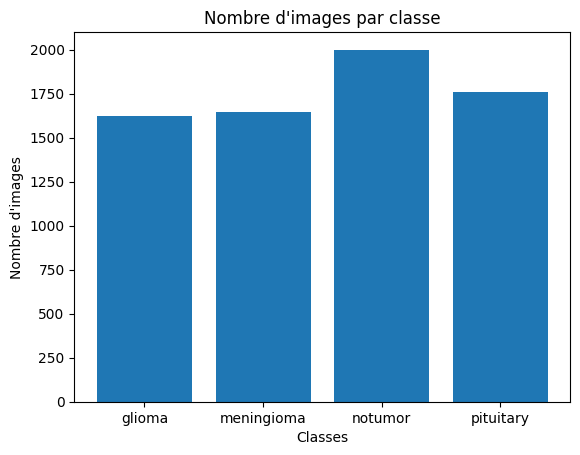

In [7]:

from matplotlib import image

plt.figure(figsize=(10,10))
n_images = min(9, len(images))

for i in range(n_images):
    ax = plt.subplot(3,3,i+1)
    image_rgb = cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB)
    plt.imshow(image_rgb)
    nom_class = next((k for k, v in labels_par_dossier.items() if v == labels[i]), None)
    plt.title(nom_class)
plt.show()

effectifs = Counter(labels)

noms_classes = list(labels_par_dossier.keys())
nombres_images = [
    effectifs[labels_par_dossier[nom]]
    for nom in noms_classes
]

for nom, nombre in zip(noms_classes, nombres_images):
    print(f'{nom} : {nombre} images')

plt.bar(noms_classes, nombres_images)
plt.title("Nombre d'images par classe")
plt.xlabel('Classes')
plt.ylabel("Nombre d'images")
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

def spliting_data(X, y):
    X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RAMDOM_STATE)
    X_test, X_val, y_test, y_val = train_test_split(X_tmp, y_tmp, test_size=0.5,  stratify=y_tmp, random_state=RAMDOM_STATE)
    print(X_train.shape, X_test.shape, X_val.shape)
    print(y_train.shape, y_test.shape, y_val.shape)

    return  X_train, X_test, X_val, y_train, y_test, y_val
    
X_train, X_test, X_val, y_train, y_test, y_val = spliting_data(images_array_2d, labeles_array_2d)
    
def  normalisation(X, seuil):
    return X.astype('float32') / seuil
    
def prep(X, y, training=True):
    X = normalisation(X, 255.0)
    if training:
        datagen_a = ImageDataGenerator(rotation_range=15, width_shift_range=0.1, height_shift_range=0.1, horizontal_flip=True, fill_mode='nearest')
        datagen_a.fit(X)
    X_ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        X_ds = X_ds.shuffle(buffer_size=X_ds.cardinality())
        
    X_ds = X_ds.batch(batch_size=BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

    return X_ds

Train_ds =  prep(X_train, y_train, training=True)
Test_ds = prep(X_test, y_test, training=False)
Val_ds = prep(X_val, y_val, training=False)
print(Train_ds, Test_ds, Val_ds)

(5618, 224, 224, 3) (702, 224, 224, 3) (703, 224, 224, 3)
(5618,) (702,) (703,)


I0000 00:00:1792170217.791242      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792170217.795030      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))> <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))> <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


In [9]:
for image_batch, label_batch in Train_ds:
    print(image_batch.shape)
    print(label_batch.shape)
    break

(32, 224, 224, 3)
(32,)


In [10]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 173056)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │    11,075,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,132,618 (42.47 MB)

 Trainable params: 11,132,618 (42.47 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 173056)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │    11,075,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,133,972 (42.47 MB)

 Trainable params: 11,133,972 (42.47 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, BackupAndRestore
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])
filepath = f"../models/nest_mode.keras"
checkpoint = ModelCheckpoint(filepath,monitor='val_accuracy', verbose=1, save_best_only=True, mode='max')
callback = EarlyStopping(monitor='loss',patience=3, mode='min', restore_best_weights=True)
backup = BackupAndRestore(
    '/kaggele/working/backup', save_freq="epoch", double_checkpoint=True, delete_checkpoint=False
)

In [15]:
history = model.fit(Train_ds, epochs=EPOCHS, 
                    validation_data=(Val_ds), batch_size=BATCH_SIZE, callbacks=[checkpoint, callback, backup])

Epoch 1/15


2026-10-16 17:03:55.729492: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 17:03:55.877723: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  3/176 ━━━━━━━━━━━━━━━━━━━━ 8s 47ms/step - accuracy: 0.2135 - loss: 2.8667 

I0000 00:00:1792170238.445896     148 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.5397 - loss: 1.2523

2026-10-16 17:04:07.767433: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 17:04:07.913067: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5406 - loss: 1.2498
Epoch 1: val_accuracy improved from None to 0.81081, saving model to ../models/nest_mode.keras

Epoch 1: finished saving model to ../models/nest_mode.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 23s 89ms/step - accuracy: 0.6867 - loss: 0.8038 - val_accuracy: 0.8108 - val_loss: 0.4812
Epoch 2/15
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8629 - loss: 0.3579
Epoch 2: val_accuracy improved from 0.81081 to 0.91892, saving model to ../models/nest_mode.keras

Epoch 2: finished saving model to ../models/nest_mode.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - accuracy: 0.8761 - loss: 0.3288 - val_accuracy: 0.9189 - val_loss: 0.2583
Epoch 3/15
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9471 - loss: 0.1495
Epoch 3: val_accuracy did not improve from 0.91892
176/176 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - accuracy: 0.9464 - loss: 0.1513 - val_accuracy: 0.9175 - val_loss: 0.2482
Epoch 4/15
176/176 ━━━━━━━━━━

In [16]:
X = model.predict(Test_ds)
X

22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step


array([[ -6.2419143 ,   8.999805  ,   0.26763543, ..., -21.793812  ,
        -15.789218  ,  -5.066715  ],
       [ 15.560461  ,  11.459156  ,  -1.5091877 , ...,  -8.124583  ,
         -6.62619   , -12.2941    ],
       [-10.865742  ,  22.423857  ,  38.321865  , ...,  -9.622765  ,
        -15.500821  ,  -7.855027  ],
       ...,
       [ 11.3806305 ,  16.483345  ,   2.9865866 , ...,  -7.851548  ,
         -3.304599  ,  -9.725647  ],
       [ -1.5160941 ,  21.123775  ,  38.902527  , ...,  -7.260086  ,
        -13.565036  , -12.815161  ],
       [ -0.30503327,  33.756115  ,  24.611336  , ...,  -8.238608  ,
        -10.812721  ,  -8.932864  ]], dtype=float32)

In [17]:
np.argmax(X[0])

np.int64(3)

22/22 - 1s - 35ms/step - accuracy: 0.9587 - loss: 0.2572


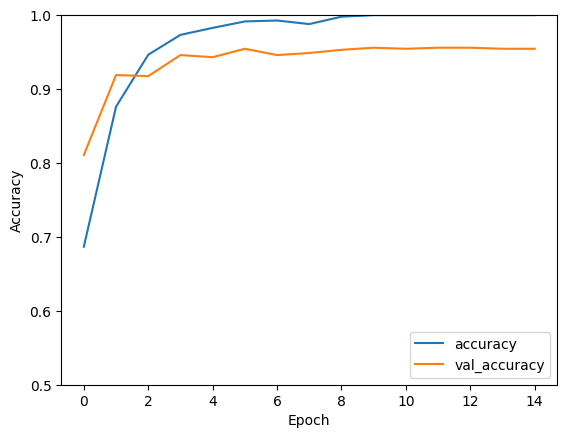

In [18]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(Test_ds, verbose=2)

In [19]:
Y = best_model.predict(Test_ds)

NameError: name 'best_model' is not defined

In [ ]:
np.argmax(Y[0])

In [ ]:
model.save('best_model.keras')